# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Buhangin, Ahrystan Deniz
- _Student No._: 2024-07766
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="Figures/integrationgraphs.png" alt="Alt text" width=100%>

### Report discussion

The first column represents the absolute error vs. the number of divisions for each test function. Unsurprisingly, both implementations of Simpson's rule outspeed the decrease in absolute error as N is increased of the Trapezoidal method. This is much more apparent, however, in the second test function where both Simpson's implementations reach a magnitude of e-16 absolute error in just about a N=100. As for the second column, it shows a visualization of the 'shotgun method' of integration via Monte Carlo. We can see a legion of points scattered around the area of a bounding rectangle wherein a portion of the points land inside the bounded region of the curve. Blue points represent those that are above 0 and red points represent otherwise, the gray points simply represent points that are outside the curve.


The Monte Carlo method converges to a value due to the fact that probabilistically, the total number of guesses thrown within some region with a known area can be related to the number of guesses in that region that so happens to be within the region bounded by our curve. The Monte Carlo method, however, is eclipsed by Newton-Cotes methods in several cases. One such case is when our function is smooth and continuous where Newton-Cotes methods tend to work extremely fast and efficiently. Another very notable case is the innate deterministic advantage Newton-Cotes methods have compared to the Monte Carlo, as it is subject to variance due to random sampling. The Monte Carlo method is strong when it is particularly used in higher dimensional analysis, due to its general independence with dimensionality.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sc

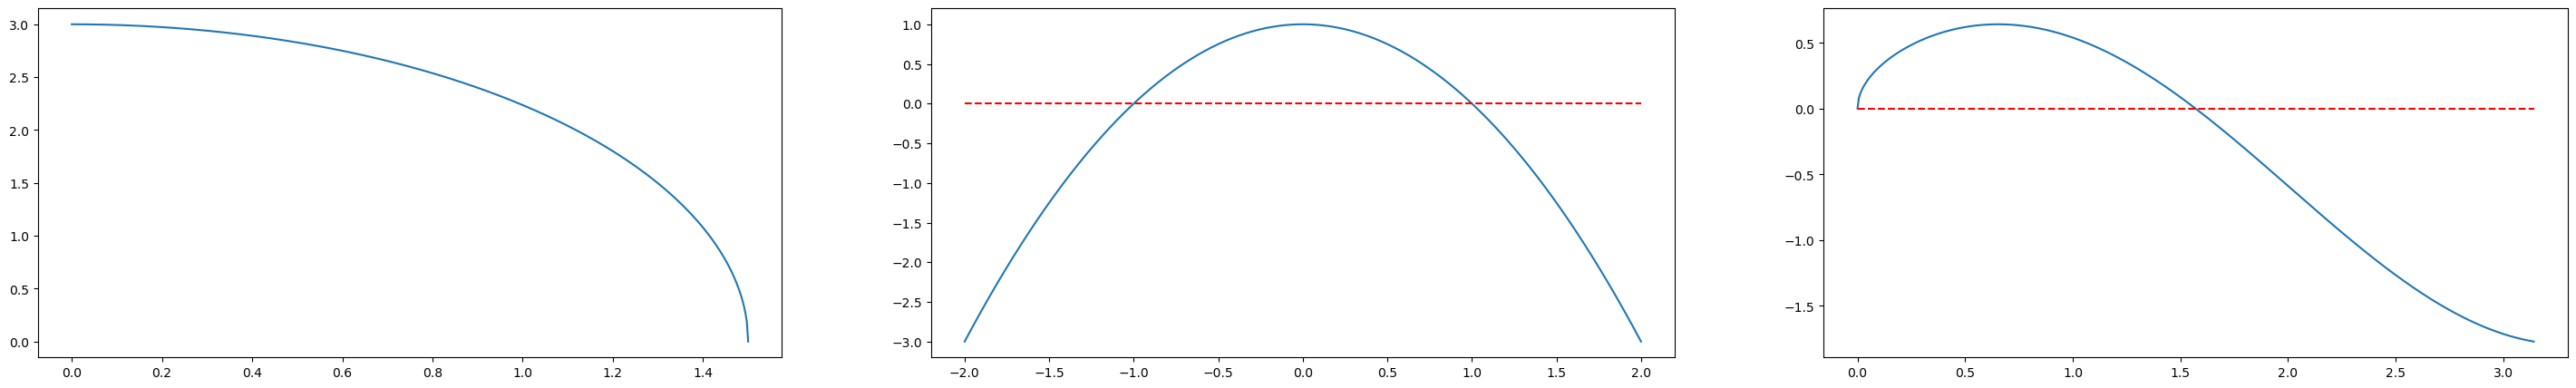

In [3]:
# Define test functions along with function that returns a linear space given some parameters

def dom(start, end, res=500):
    return np.linspace(start, end, res)

def test_1(x):
    return np.sqrt(9 - 4 * x**2)

def test_2(x):
    return -(x**2) + 1

def test_3(x):
    return np.cos(x)*np.sqrt(x)

x_1, x_2, x_3 = dom(0, 3/2), dom(-2, 2), dom(0, np.pi)

# Plot the test functions

fig, ax = plt.subplots(1, 3, figsize=(36,5))
ax[0].plot(x_1, test_1(x_1))
ax[1].plot(x_2, test_2(x_2))
ax[1].plot(x_2, x_2 - x_2, 'r--')
ax[2].plot(x_3, test_3(x_3))
ax[2].plot(x_3, x_3 - x_3, 'r--')

In [4]:
# Define all the needed functions

def monte_carlo(f, a, b, tot=False, N=500):
    x_rand = np.random.uniform(a, b, N)
    if tot == False: # add this parameter to every function, allows us to calculate the total area bounded if tot==True
        y = f(x_rand)
    else:
        y = np.abs(f(x_rand))
    estimate = (b - a)*np.mean(y)
    return estimate, x_rand

def trapezoidal(f, a, b, tot=False, N=50):
    x = dom(a, b, N+1)
    h = (b - a) / N
    if tot == False:
        y=f(x)
    else:
        y = np.abs(f(x))
    y_right = y[1:]
    y_left = y[:-1]
    estimate = (h / 2) * np.sum(y_right + y_left)
    return estimate

def simp_13(f, a, b, tot=False, N=100):
    x = dom(a, b, N+1)
    h = (b - a) / N
    cs = 2*np.ones(N+1)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1
    if tot == False:
        y = f(x)
    else:
        y = np.abs(f(x))
    contribs = cs*y
    estimate = (h / 3)*np.sum(contribs)
    return estimate

def simp_38(f, a, b, tot=False, N=102):
    x = dom(a, b, N+1)
    h = (b - a) / N
    cs = 3*np.ones(N+1)
    cs[3::3] = 2; cs[0] = 1; cs[-1] = 1
    if tot == False:
        y = f(x)
    else:
        y = np.abs(f(x))
    contribs = cs*y
    estimate = ((3*h)/8)*np.sum(contribs)
    return estimate

# Define reusable function for printing 

def print_calculations(fn, a, b):
    print('For function:', fn.__name__)
    print('    True value of signed area:', sc.integrate.quad(fn, a , b)[0])
    print("    Signed area:")
    print('        Monte Carlo:', monte_carlo(fn, a, b, 0, 1000000)[0])
    print('        Trapezoidal:', trapezoidal(fn, a, b, 0, 50))
    print("        Simpson's 1/3:", simp_13(fn, a, b))
    print("        Simpson's 3/8:", simp_38(fn, a, b))
    print('    Total bounded area:')
    print('        Monte Carlo:', monte_carlo(fn, a, b, 1, 1000000)[0])
    print('        Trapezoidal:', trapezoidal(fn, a, b, 1, 50))
    print("        Simpson's 1/3:", simp_13(fn, a, b, 1))
    print("        Simpson's 3/8:", simp_38(fn, a, b, 1))
    return

print_calculations(test_1, 0, 3/2)
print_calculations(test_2, -2, 2)
print_calculations(test_3, 0, np.pi)

For function: test_1
    True value of signed area: 3.534291735288518
    Signed area:
        Monte Carlo: 3.5339196239475834
        Trapezoidal: 3.530552074985812
        Simpson's 1/3: 3.5337748560066307
        Simpson's 3/8: 3.533680777065092
    Total bounded area:
        Monte Carlo: 3.533551736970919
        Trapezoidal: 3.530552074985812
        Simpson's 1/3: 3.5337748560066307
        Simpson's 3/8: 3.533680777065092
For function: test_2
    True value of signed area: -1.3333333333333335
    Signed area:
        Monte Carlo: -1.3320424237593917
        Trapezoidal: -1.3376000000000001
        Simpson's 1/3: -1.3333333333333337
        Simpson's 3/8: -1.3333333333333333
    Total bounded area:
        Monte Carlo: 4.000002558940817
        Trapezoidal: 4.0064
        Simpson's 1/3: 3.9978666666666673
        Simpson's 3/8: 4.0
For function: test_3
    True value of signed area: -0.8948314694841447
    Signed area:
        Monte Carlo: -0.8934123673511482
        Trapezoidal

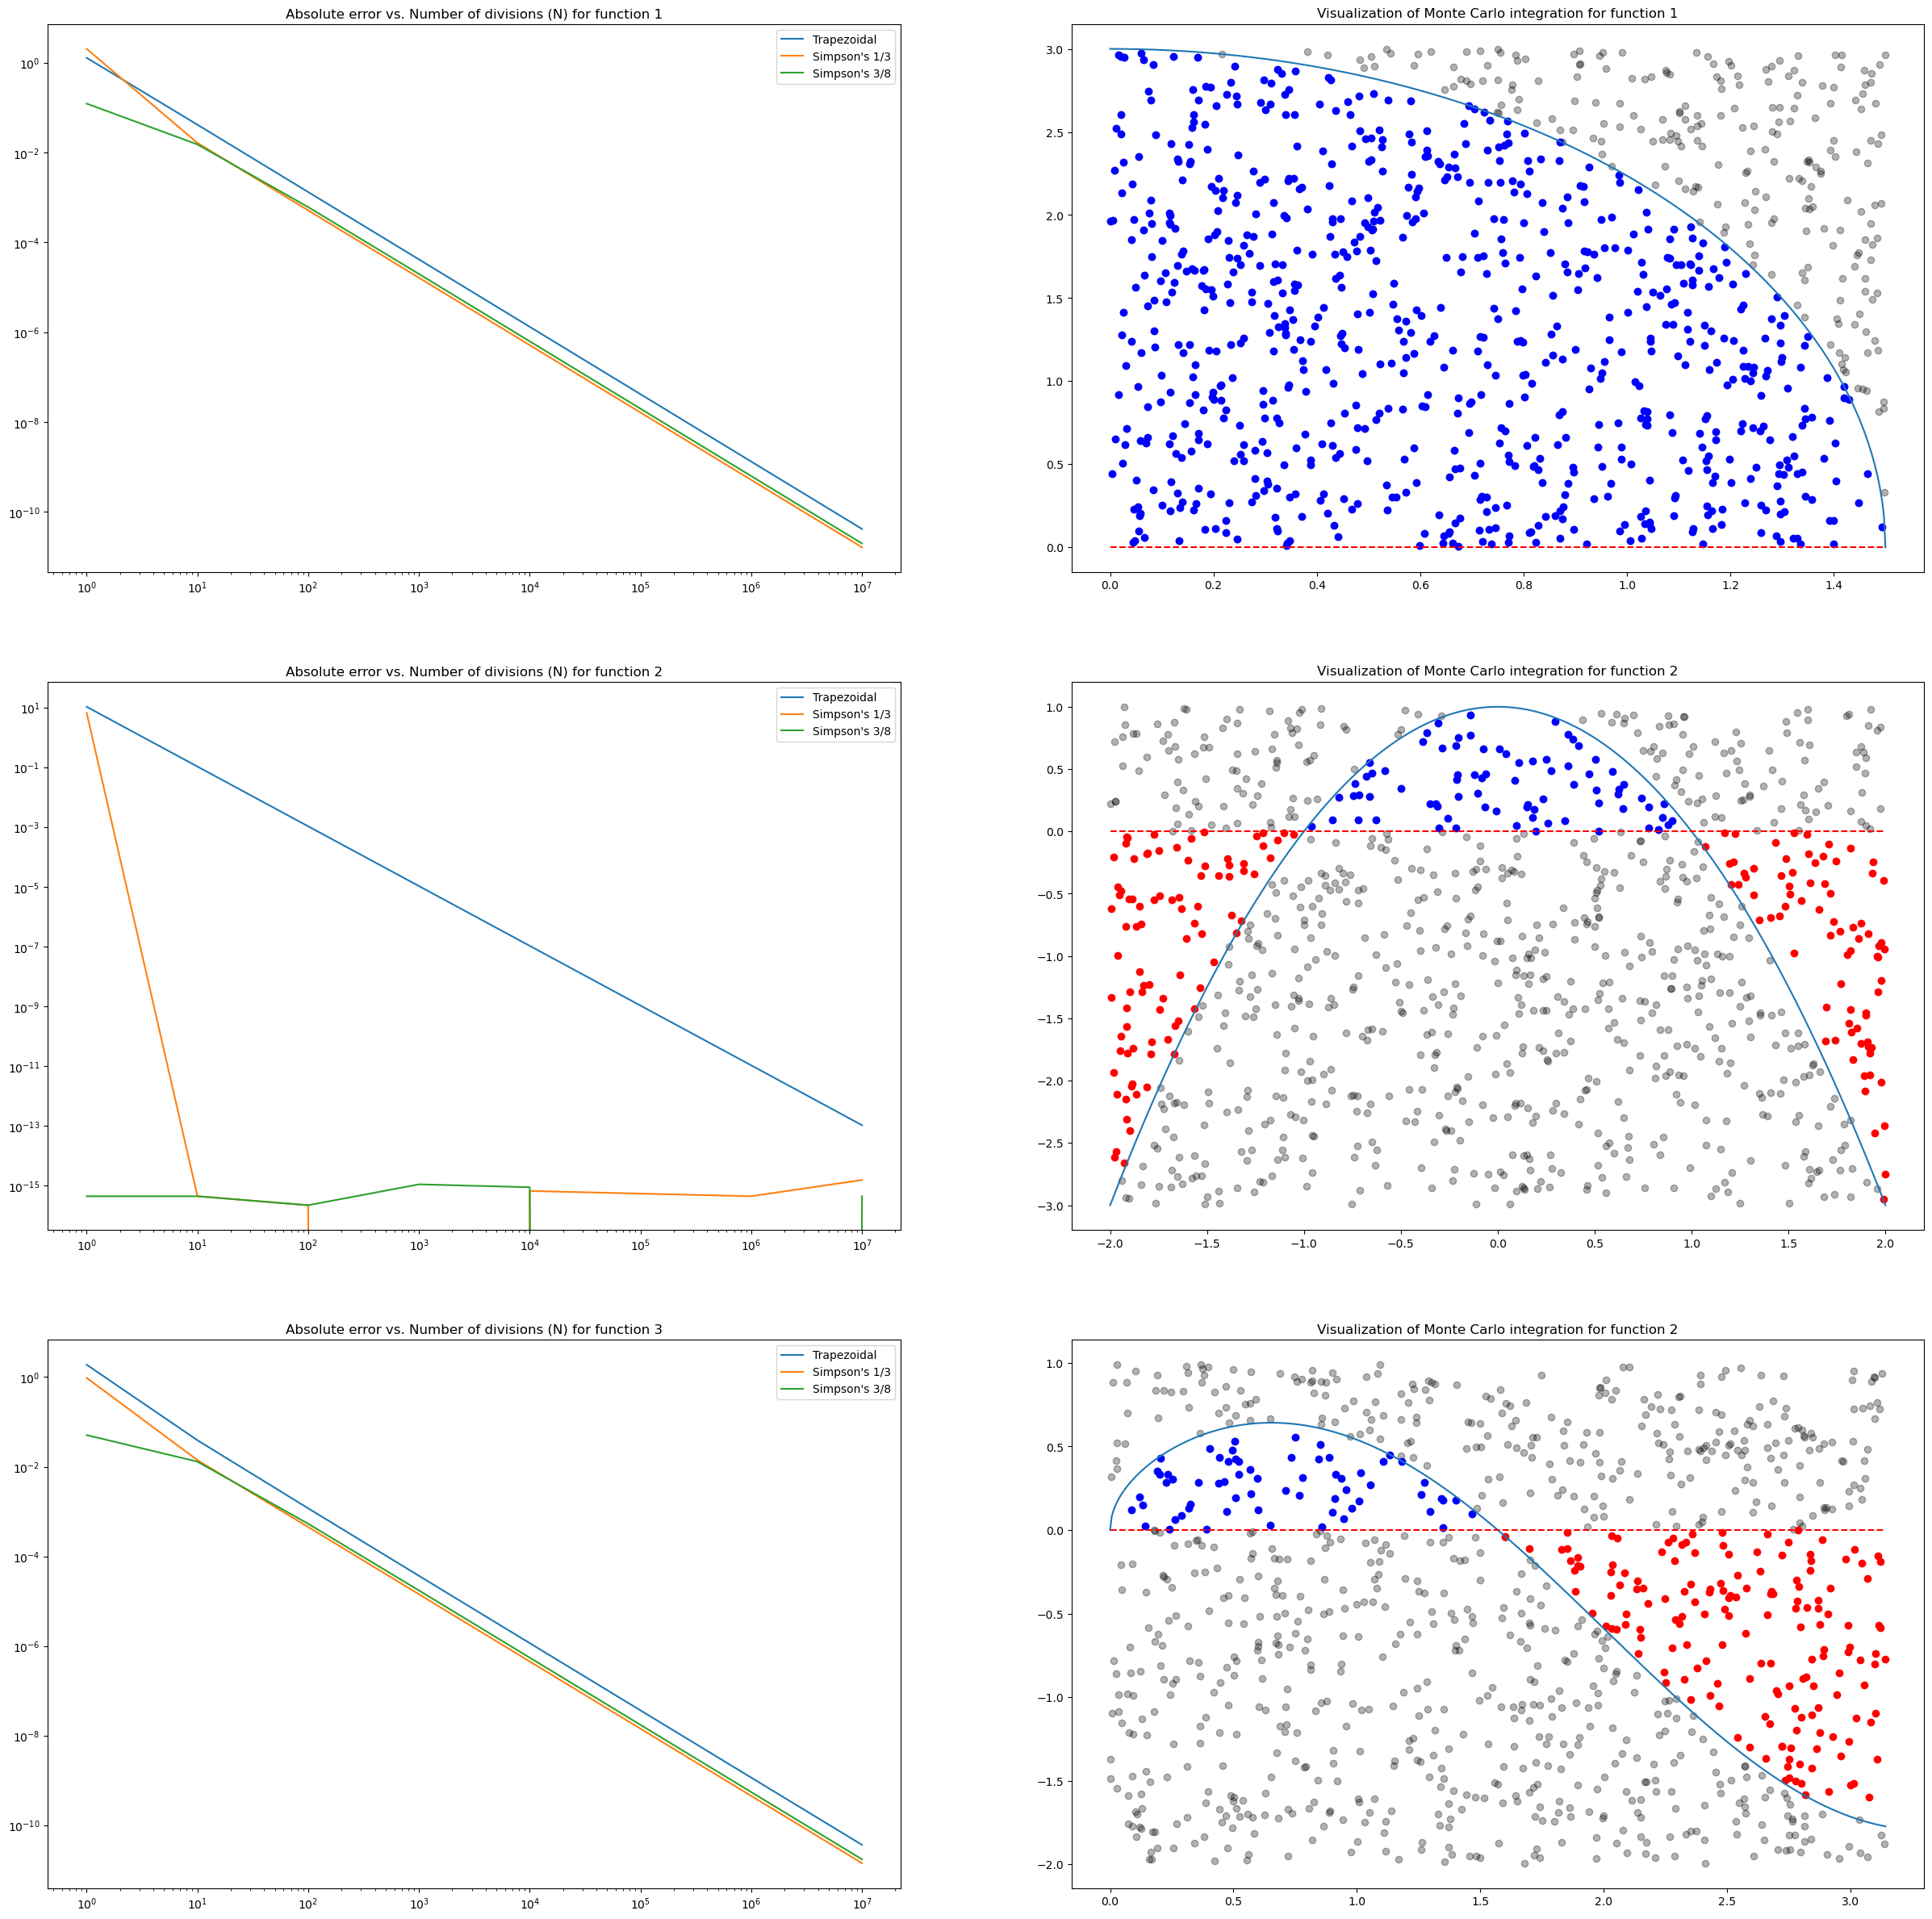

In [5]:
N = [1, 10, 100, 1000, 10000, 10000, 1000000, 1000000, 10000000]

# Tedious plotting, shortened code a bit using defined functions

def get_Error(f, a, b):
    true = sc.integrate.quad(f, a, b)[0]
    error_trap = []
    error_simp13 = []
    error_simp38 = []
    for n in N:
        tr = np.abs(true - trapezoidal(f, a, b, 0, n))
        simp13 = np.abs(true - simp_13(f, a, b, 0, n))
        simp38 = np.abs(true - simp_38(f, a, b, 0, n+2))
        error_trap.append(tr)
        error_simp13.append(simp13)
        error_simp38.append(simp38)
        
    return error_trap, error_simp13, error_simp38

def visualize_mc(f, a, b, y_min, y_max, N = 1000):
    x_rand = monte_carlo(f, a, b, 0, N)[1]
    y_rand = np.random.uniform(y_min, y_max, N)
    over_zero = (y_rand <= f(x_rand)) & (y_rand > 0)
    under_zero = (y_rand >= f(x_rand)) & (y_rand < 0)
                                         
    return x_rand, y_rand, over_zero, under_zero

err_1 = get_Error(test_1, 0, 3/2)
err_2 = get_Error(test_2, -2, 2)
err_3 = get_Error(test_3, 0, np.pi)

vmc_1x, vmc_1y, vmc_1over, vmc_1under  = visualize_mc(test_1, 0, 3/2, 0, 3)
vmc_2x, vmc_2y, vmc_2over, vmc_2under = visualize_mc(test_2, -2, 2, -3, 1)
vmc_3x, vmc_3y, vmc_3over, vmc_3under = visualize_mc(test_3, 0, np.pi, -2, 1)

y_min, y_max = -2, 1
x_rand = monte_carlo(test_2, 0, np.pi, 0, 1000)[1]
y_rand = np.random.uniform(y_min, y_max, 1000)

over_zero = (y_rand <= test_3(x_rand)) & (y_rand > 0) # Crazy you can do this
under_zero = (y_rand >= test_3(x_rand)) & (y_rand < 0)



fig, ax = plt.subplots(3,2, figsize=(30, 30))
                                    
ax[0][0].set_xscale('log')
ax[0][0].set_yscale('log')
#ax[0][0].scatter(np.array(N), np.array(error_trap))
ax[0][0].plot(np.array(N), np.array(err_1[0]), label='Trapezoidal')
ax[0][0].plot(np.array(N), np.array(err_1[1]), label="Simpson's 1/3")
ax[0][0].plot(np.array(N), np.array(err_1[2]), label="Simpson's 3/8")
ax[0][0].legend()
ax[0][0].set_title("Absolute error vs. Number of divisions (N) for function 1")
ax[0][1].scatter(vmc_1x[~vmc_1under], vmc_1y[~vmc_1under], color='black', alpha=0.3)
ax[0][1].scatter(vmc_1x[vmc_1over], vmc_1y[vmc_1over], color='blue')
ax[0][1].scatter(vmc_1x[vmc_1under], vmc_1y[vmc_1under], color='red')
ax[0][1].plot(x_1, test_1(x_1))
ax[0][1].plot(x_1, x_1 - x_1, 'r--')
ax[0][1].set_title("Visualization of Monte Carlo integration for function 1")

ax[1][0].set_xscale('log')
ax[1][0].set_yscale('log')
#ax[0][0].scatter(np.array(N), np.array(error_trap))
ax[1][0].plot(np.array(N), np.array(err_2[0]), label='Trapezoidal')
ax[1][0].plot(np.array(N), np.array(err_2[1]), label="Simpson's 1/3")
ax[1][0].plot(np.array(N), np.array(err_2[2]), label="Simpson's 3/8")
ax[1][0].legend()
ax[1][0].set_title("Absolute error vs. Number of divisions (N) for function 2")
ax[1][1].scatter(vmc_2x[~vmc_2under], vmc_2y[~vmc_2under], color='black', alpha=0.3)
ax[1][1].scatter(vmc_2x[vmc_2over], vmc_2y[vmc_2over], color='blue')
ax[1][1].scatter(vmc_2x[vmc_2under], vmc_2y[vmc_2under], color='red')
ax[1][1].plot(x_2, test_2(x_2))
ax[1][1].plot(x_2, x_2 - x_2, 'r--')
ax[1][1].set_title("Visualization of Monte Carlo integration for function 2")

ax[2][0].set_xscale('log')
ax[2][0].set_yscale('log')
#ax[0][0].scatter(np.array(N), np.array(error_trap))
ax[2][0].plot(np.array(N), np.array(err_3[0]), label='Trapezoidal')
ax[2][0].plot(np.array(N), np.array(err_3[1]), label="Simpson's 1/3")
ax[2][0].plot(np.array(N), np.array(err_3[2]), label="Simpson's 3/8")
ax[2][0].legend()
ax[2][0].set_title("Absolute error vs. Number of divisions (N) for function 3")
ax[2][1].scatter(vmc_3x[~vmc_3under], vmc_3y[~vmc_3under], color='black', alpha=0.3)
ax[2][1].scatter(vmc_3x[vmc_3over], vmc_3y[vmc_3over], color='blue')
ax[2][1].scatter(vmc_3x[vmc_3under], vmc_3y[vmc_3under], color='red')
ax[2][1].plot(x_3, test_3(x_3))
ax[2][1].plot(x_3, x_3 - x_3, 'r--')
ax[2][1].set_title("Visualization of Monte Carlo integration for function 2")
plt.savefig('/home/jovyan/Buhangin_AP155/AP155_TX1_1sAY2627/ahrystanB/Figures/integrationgraphs.png')